# REFMAP laboratory listening test 1 & 2 analysis: Psychoacoustic annoyance models

## Setup

In [1]:
# -*- coding: utf-8 -*-
import sys
import os
# Build a path from the notebook's parent directory to the python modules
module_path = os.path.abspath(os.path.join('..'))

# Add to sys.path if not already present
if module_path not in sys.path:
    sys.path.append(module_path)

# import statements
import numpy as np
import pandas as pd
from PyQt5.QtWidgets import QFileDialog, QApplication
from scipy import stats
from scipy import optimize
import warnings
import matplotlib as mpl
from matplotlib import pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import pingouin as pg
from numpy.random import Generator, PCG64
from refmap_psychoacoustics.utils.format_helpers import display_round, round_trad

In [2]:
# set plot parameters
sns.set_style('white')
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = 'Times New Roman'
mpl.rcParams.update({'font.size': 16})
mpl.rcParams['figure.autolayout'] = True
mpl.rcParams['mathtext.fontset'] = 'stix'

SMALL_SIZE = 12
MEDIUM_SIZE = 14
BIGGER_SIZE = 16

plt.rc('font', size=SMALL_SIZE)          # controls default text sizes
plt.rc('axes', titlesize=MEDIUM_SIZE,
       labelsize=MEDIUM_SIZE)    # fontsize of the axes title and x and y labels
plt.rc('xtick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('ytick', labelsize=SMALL_SIZE)    # fontsize of the tick labels
plt.rc('legend', fontsize=SMALL_SIZE)    # legend fontsize
plt.rc('figure', titlesize=BIGGER_SIZE)  # fontsize of the figure title

mycolours = [(0, 102, 255), (0, 204, 153), (255, 0, 102), (74, 111, 152),
             (251, 164, 49), (204, 153, 255), (90, 192, 255), (80, 245, 233),
             (255, 90, 192), (164, 201, 242), (255, 254, 139), (255, 243, 255)]
mycolours = [tuple(shade/255 for shade in colour) for colour in mycolours]

numpy_randomGen = Generator(PCG64(303))

# enable copy-on-write mode for Pandas (will be default from Pandas 3.0)
pd.options.mode.copy_on_write = True

# check/open QApplication instance
if not QApplication.instance():
    app = QApplication(sys.argv)
else:
    app = QApplication.instance() 

# setup ipython autoreloading magic
# %load_ext autoreload
# %autoreload 2

Set the saveplots toggle to True if plot saving is desired:

In [3]:
saveplots=True

if saveplots:
    # select figure output save path
    outFigPath = QFileDialog.getExistingDirectory(caption=r"Select output folder to save plots '03 Experiment\Experiment 2\Analysis\Plots'")

    # create subfolders if not already existing
    try:
        os.mkdir(os.path.join(outFigPath, "svg"))
    except FileExistsError:
        pass

    try:
        os.mkdir(os.path.join(outFigPath, "pdf"))
    except FileExistsError:
        pass


In [11]:
savedata = True

if savedata:
    # select data output save path
    outDataPath = QFileDialog.getExistingDirectory(caption=r"Select output folder to save output data in: \03 Experiment\Experiment 2\Analysis\Python")


## Functions

In [4]:
def calc_pa(loud, sharp, tonal, rough, fluctuation, impulsive,
                sharp_a, sharp_b, tonal_a, tonal_b, rough_a, rough_b,
                fluctuation_a, fluctuation_b, impulsive_a, impulsive_b):

    sharp_w = sharp_a*sharp/loud**sharp_b
    tonal_w = tonal_a*tonal/loud**tonal_b
    rough_w = rough_a*rough/loud**rough_b
    fluctuation_w = fluctuation_a*fluctuation/loud**fluctuation_b
    impulsive_w = impulsive_a*impulsive/loud**impulsive_b

    pa = loud*(1 + np.sqrt(sharp_w**2 + tonal_w**2 + rough_w**2
                           + fluctuation_w**2 + impulsive_w**2))

    return pa

In [5]:
def sigmoid_richards(x, lower=0, upper=1, b=1, q=1, v=1):
    """
    Sigmoid function with the Richards growth model.

    Parameters:
    -----------
    x : array-like
        Input values for the sigmoid function.

    lower : float, optional
        The lower asymptote of the sigmoid function. Default is 0.
    
    b : float, optional
        The growth rate (change in slope) of the sigmoid function. Default is 1.
    
    upper : float, optional
        The upper asymptote of the sigmoid function. Default is 1.

    q : float, optional
        The scale parameter of the sigmoid function. Default is 1.
    
    v : float, optional
        The shape parameter of the sigmoid function. Default is 1.
    """

    if v == 0:
        raise ValueError("Parameter 'v' must be non-zero to avoid division by zero.")

    if q <= 0:
        raise ValueError("'q' must be positive.")
    
    if upper <= lower:
        raise ValueError("Parameter 'upper' must be greater than 'lower' to ensure a valid sigmoid shape.")

    expo = np.clip(-b * np.asarray(x, dtype=float), -700, 700)
    y = lower + (upper - lower)/(1 + q*np.exp(expo))**(1/v)
    
    return y

In [17]:
def sigmoid_gompertz(x, lower=0, upper=1, b=1, c=1):
    """
    Sigmoid function with the Gompertz growth model.

    Parameters:
    -----------
    x : array-like
        Input values for the sigmoid function.

    lower : float, optional
        The lower asymptote of the sigmoid function. Default is 0.
    
    b : float, optional
        The growth rate (change in slope) of the sigmoid function. Default is 1.
    
    upper : float, optional
        The upper asymptote of the sigmoid function. Default is 1.

    c : float, optional
            The scale parameter of the sigmoid function. Default is 1.
    
    """
    
    if c <= 0:
        raise ValueError("'c' must be positive.")
    
    if upper <= lower:
        raise ValueError("Parameter 'upper' must be greater than 'lower' to ensure a valid sigmoid shape.")

    z = np.clip(np.log(c) - b * np.asarray(x, dtype=float), -700, 700)
    y = lower + (upper - lower) * np.exp(-np.exp(z))
    
    return y

In [ ]:
def sigmoid_richards_inverse(y, lower=0.0, upper=1.0, b=1.0, q=1.0, v=1.0):
    """Inverse of sigmoid_richards (ma back to pa).
 
    Only defined for lower < y < upper. Values on or beyond an asymptote have
    no finite pa, so they come back as NaN (with a warning).
    """
    y = np.asarray(y, dtype=float)
    outside = (y <= lower) | (y >= upper)
    if np.any(outside):
        warnings.warn(f"{outside.sum()} value(s) outside ({lower}, {upper}); "
                      "returning NaN for them.")
        y = np.where(outside, np.nan, y)
    span = upper - lower
    return -np.log(((span / (y - lower)) ** v - 1.0) / q) / b
 

In [18]:
def sigmoid_gompertz_inverse(y, lower=0.0, upper=1.0, b=1.0, c=1.0):
    """Inverse of gompertz (ma back to pa).
 
    Only defined for lower < y < upper. Values on or beyond an asymptote have
    no finite pa, so they come back as NaN (with a warning).
    """
    y = np.asarray(y, dtype=float)
    outside = (y <= lower) | (y >= upper)
    if np.any(outside):
        warnings.warn(f"{outside.sum()} value(s) outside ({lower}, {upper}); "
                      "returning NaN for them.")
        y = np.where(outside, np.nan, y)
    fraction = (y - lower) / (upper - lower)        # position within the span, 0-1
    return -np.log(-np.log(fraction) / c) / b
 

In [24]:
# Default bounds (lower, upper) -- ADJUST THESE to your data / units.
# The sigmoid growth rate 'sig_b' in particular depends on the scale of pa.
DEFAULT_BOUNDS = (
    [0.0, -2.0] * 5 + [1e-4, 1e-3],     # lower bounds
    [10.0, 2.0] * 5 + [5.0, 100.0],     # upper bounds
)

def optimise_pa(theta, data):
    """pa from the first 10 entries of theta. `data` is a DataFrame or dict
    with columns loud, sharp, tonal, rough, fluctuation, impulsive."""
    return calc_pa(data["loud"], data["sharp"], data["tonal"], data["rough"],
                   data["fluctuation"], data["impulsive"], *theta[:N_PA])

def optimise_ma(theta, data, lower, upper):
    """Full chain: inputs -> pa -> predicted observation scale."""
    pa = optimise_pa(theta, data)
    sb, sc = theta[N_PA:]
    return sigmoid_gompertz(pa, lower=lower, upper=upper, b=sb, c=sc)

def pa_from_ma(obs, theta, lower, upper):
    """Map ma observations back onto the pa scale using fitted sigmoid params."""
    sb, sc = theta[N_PA:]
    return sigmoid_gompertz_inverse(obs, lower=lower, upper=upper,
                                    b=sb, c=sc)
 
def residuals(theta, data, obs, lower, upper, weights=None):
    """predicted - observed, one value per stimulus (what least_squares needs).
 
    With weights, each residual is multiplied by sqrt(weight), so that the
    SQUARED residual is multiplied by the weight.
    """
    with np.errstate(all="ignore"):
        res = np.asarray(optimise_ma(theta, data, lower, upper)) - obs
    if weights is not None:
        res = res * np.sqrt(weights)
    # An extreme trial parameter set can give inf/NaN predictions. Replace
    # them with a huge residual so the optimiser steers away instead of crashing.
    return np.where(np.isfinite(res), res, 1e6)
 
 
def objective(theta, data, obs, lower, upper, weights=None):
    """Scalar objective: (weighted) sum of squared errors."""
    return np.sum(residuals(theta, data, obs, lower, upper, weights) ** 2)

def fit(data, obs, lower, upper, weights=None, bounds=DEFAULT_BOUNDS,
        loss="linear", f_scale=1.0, seed=0, de_kwargs=None):
    """Fit theta to the observations. Returns (params, predictions, result).
 
    loss    : passed straight to scipy's least_squares: 'linear' (squared
              error), or a robust loss: 'soft_l1', 'huber', 'cauchy', 'arctan'.
    f_scale : residual size treated as 'normal' by the robust losses. With
              weights it is in units of standard errors (try 1-3); without,
              in observation units.
    de_kwargs : overrides for differential_evolution (e.g. maxiter, popsize).
 
    Note: stage 1 always minimises plain (weighted) squared error, whatever
    `loss` is; only stage 2 uses `loss`. Stage 1 just has to land in the right
    region, and stage 2 then finds the minimum of the chosen loss there.
    """
    obs = np.asarray(obs, dtype=float)
    lb, ub = np.asarray(bounds[0], float), np.asarray(bounds[1], float)
    args = (data, obs, lower, upper, weights)
 
    settings = dict(maxiter=300, popsize=20, tol=1e-8, polish=False, seed=seed)
    settings.update(de_kwargs or {})
    stage1 = optimize.differential_evolution(objective, list(zip(lb, ub)),
                                    args=args, **settings)
 
    result = optimize.least_squares(residuals, stage1.x, bounds=(lb, ub), args=args,
                           loss=loss, f_scale=f_scale, x_scale="jac")
 
    at_bound = np.isclose(result.x, lb) | np.isclose(result.x, ub)
    if at_bound.any():
        warnings.warn("Parameters at a bound (consider widening it): "
                      + ", ".join(np.array(PARAM_NAMES)[at_bound]))
 
    params = pd.Series(result.x, index=PARAM_NAMES)
    predictions = np.asarray(optimise_ma(result.x, data, lower, upper))
    return params, predictions, result
 

## Import data and organise

In [8]:
# import data
fileExts = "*.csv"

dataByStimTestFilePath = list(QFileDialog.getOpenFileName(filter="refmap_listest1_2_testdataMerge_ByStim.csv",
                                                       caption=r"Open refmap_listest1_2_testdataMerge_ByStim.csv in: \03 Experiment\Experiment 2\Analysis\PostProcess"))[0]
dataByStimTest = pd.read_csv(dataByStimTestFilePath, index_col=0)


## PA model optimisation for absolute annoyance

In [25]:
BIG = 1e6  # penalty for non-finite predictions (keeps optimisers moving)

PA_TERMS = ["sharp", "tonal", "rough", "fluctuation", "impulsive"]
PA_PARAM_NAMES = [f"{t}_{c}" for t in PA_TERMS for c in ("a", "b")]
SIG_PARAM_NAMES = ["sig_b", "sig_c"]
PARAM_NAMES = PA_PARAM_NAMES + SIG_PARAM_NAMES
N_PA = len(PA_PARAM_NAMES)  # 10
 

SELECTED_BOUNDS = (
    [0.0, -2.0] * 5 + [1e-4, 1e-3],     # lower bounds
    [10.0, 2.0] * 5 + [5.0, 100.0],     # upper bounds
)

LOWER = 0
UPPER = 10

data = pd.DataFrame(dict(
        loud=dataByStimTest["LoudECMAPowAvg"],
        sharp=dataByStimTest["SharpAurSHM05Ex"],
        tonal=dataByStimTest["TonalAwSHMInt05Ex"],
        rough=dataByStimTest["RoughECMA10Ex"],
        fluctuation=dataByStimTest["FluctECMA10Ex"],
        impulsive=dataByStimTest["ImpulsSHMAvg"]))

rng_seed = 99999

### Mean model

In [26]:
agg = "mean"

if agg == "mean":
    obs = dataByStimTest["AnnoyanceMean"]
    se = dataByStimTest["AnnoyanceMeanSE"]
elif agg == "median":
    obs = dataByStimTest["AnnoyanceMedian"]
    se = dataByStimTest["AnnoyanceMedianSE"]
else:
    raise ValueError("agg must be 'mean' or 'median'")

n_obs = len(obs)

floor = 0.1 * np.median(se[se > 0])             # guard against SE = 0
# weights = 1 / np.maximum(se, floor) ** 2        # inverse variance

params, pred, _ = fit(data, obs, LOWER, UPPER)                    # unweighted
mean_sq_resid = np.sum((pred - obs)**2) / (len(obs) - len(params))
mean_sq_se = np.mean(np.maximum(se, floor)**2)
tau = np.sqrt(max(0.0, mean_sq_resid - mean_sq_se))
weights = 1 / (np.maximum(se, floor)**2 + tau**2)

params, pred, result = fit(data, obs, LOWER, UPPER, weights=weights,
                        de_kwargs=dict(maxiter=100, popsize=15),
                        bounds=SELECTED_BOUNDS,
                        seed=rng_seed)

rmse = np.sqrt(np.mean((pred - obs) ** 2))
r2 = 1 - np.sum((pred - obs) ** 2) / np.sum((obs - obs.mean()) ** 2)
# ~1 means the scatter around the fit matches the standard errors
chi2 = np.sum(result.fun ** 2) / (n_obs - len(params))

print(f"\n===== Fit to {agg}s: RMSE {rmse:.3f}, R2 {r2:.4f}, "
      f"reduced chi2 {chi2:.2f} =====")

print(params.round(8).to_string())



===== Fit to means: RMSE 0.563, R2 0.8431, reduced chi2 1.09 =====
sharp_a          8.845946e+00
sharp_b          5.741116e-01
tonal_a          0.000000e+00
tonal_b          7.340873e-02
rough_a          2.683700e-03
rough_b          1.990460e+00
fluctuation_a    4.000000e-08
fluctuation_b    1.653264e+00
impulsive_a      2.206050e-03
impulsive_b      1.995888e+00
sig_b            5.175660e-02
sig_c            6.938703e+00


C:\Users\m_lot\AppData\Local\Temp\ipykernel_64712\1641141168.py:74: UserWarning: Parameters at a bound (consider widening it): tonal_a
  warnings.warn("Parameters at a bound (consider widening it): "


In [ ]:
table = pd.DataFrame(dict(
observed=obs, predicted=pred,
pa_from_obs=pa_from_ma(obs, params.values, LOWER, UPPER),
pa_from_fit=np.asarray(optimise_pa(params.values, data))),
index=dataByStimTest.index)
table.to_csv(os.path.join(outDataPath, f"pa_ma_predictions_{agg}.csv"))
print(table.head().round(3))

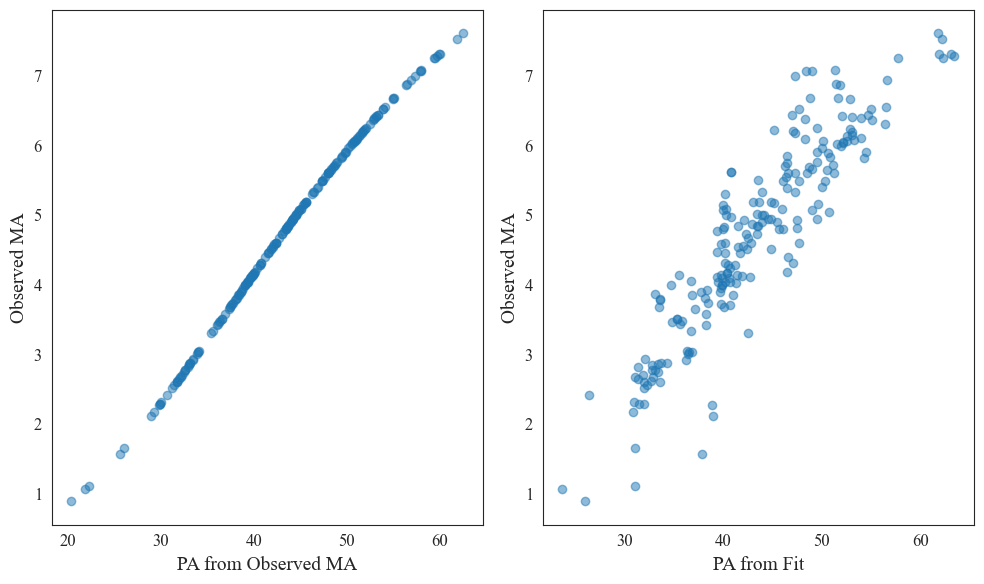

In [27]:
# plot pa_from_obs vs observed ma

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 6))

ax = axs[0]
ax.scatter(pa_from_ma(obs, params.values, LOWER, UPPER), obs, alpha=0.5)
ax.set_ylabel("Observed MA")
ax.set_xlabel("PA from Observed MA")

ax = axs[1]
ax.scatter(np.asarray(optimise_pa(params.values, data)), obs, alpha=0.5)
ax.set_ylabel("Observed MA")
ax.set_xlabel("PA from Fit")

plt.show()

In [ ]:


agg = "median"

if agg == "mean":
    obs = dataByStimTest["AnnoyanceMean"]
    se = dataByStimTest["AnnoyanceMeanSE"]
elif agg == "median":
    obs = dataByStimTest["AnnoyanceMedian"]
    se = dataByStimTest["AnnoyanceMedianSE"]
else:
    raise ValueError("agg must be 'mean' or 'median'")

n_obs = len(obs)

floor = 0.1 * np.median(se[se > 0])             # guard against SE = 0
weights = 1 / np.maximum(se, floor) ** 2        # inverse variance

params, pred, result = fit(data, obs, LOWER, UPPER, weights=weights,
                        de_kwargs=dict(maxiter=100, popsize=15),
                        seed=rng_seed)

rmse = np.sqrt(np.mean((pred - obs) ** 2))
r2 = 1 - np.sum((pred - obs) ** 2) / np.sum((obs - obs.mean()) ** 2)
# ~1 means the scatter around the fit matches the standard errors
chi2 = np.sum(result.fun ** 2) / (n_obs - len(params))

print(f"\n===== Fit to {agg}s: RMSE {rmse:.3f}, R2 {r2:.4f}, "
    f"reduced chi2 {chi2:.2f} =====")

print(params.round(4).to_string())

table = pd.DataFrame(dict(
observed=obs, predicted=pred,
pa_from_obs=pa_from_ma(obs, params.values, LOWER, UPPER)),
pa_from_fit = np.asarray(optimise_pa(params.values, data)),
index=dataByStimTest.index)
table.to_csv(os.path.join(outDataPath, f"pa_ma_predictions_{agg}.csv"))
print(table.head().round(3))


===== Fit to means: RMSE 0.572, R2 0.8379, reduced chi2 2.91 =====
sharp_a          7.3194
sharp_b          0.5997
tonal_a          0.0005
tonal_b          1.0571
rough_a          0.0003
rough_b          1.8072
fluctuation_a    0.0002
fluctuation_b    1.8929
impulsive_a      0.0001
impulsive_b      1.3815
sig_b            0.0697
sig_q            0.4455
sig_v            0.0500
            observed  predicted      pa  pa_from_obs
Experiment                                          
1              4.146      4.064  32.571       32.901
1              5.902      6.084  41.246       40.387
1              5.000      4.892  35.946       36.400
1              5.195      5.051  36.616       37.229
1              4.293      4.206  33.141       33.491


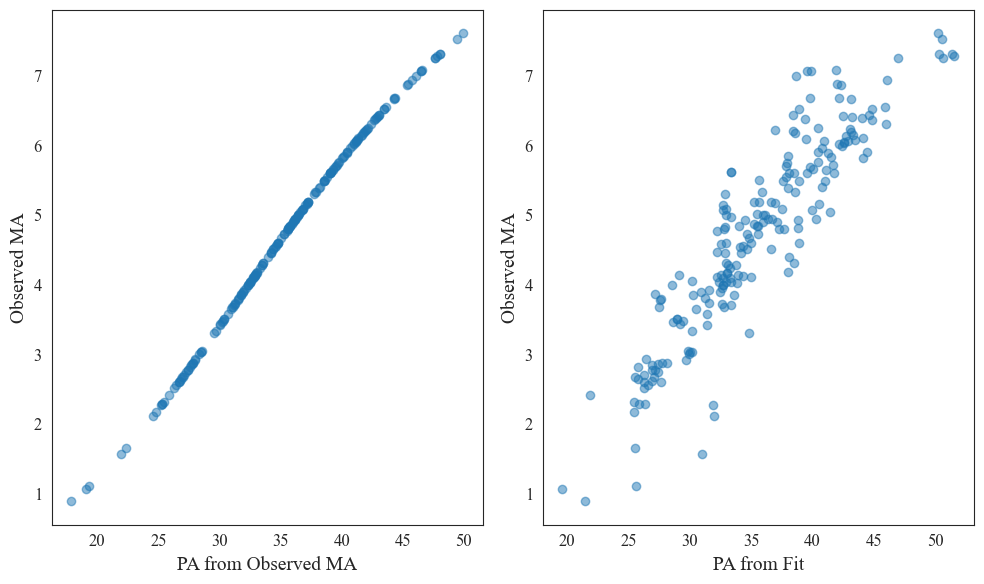

In [ ]:
# plot pa_from_obs vs observed ma

fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 6))

ax = axs[0]
ax.scatter(pa_from_ma(obs, params.values, LOWER, UPPER), obs, alpha=0.5)
ax.set_ylabel("Observed MA")
ax.set_xlabel("PA from Observed MA")

ax = axs[1]
ax.scatter(np.asarray(optimise_pa(params.values, data)), obs, alpha=0.5)
ax.set_ylabel("Observed MA")
ax.set_xlabel("PA from Fit")

plt.show()